# بازسازی کد کلاسی: عامل جاروبرقی ۴ اتاقه + چالش توسعه
**گام ۱، بند ۵ | امیرحسین نوروزی | گروه ۳**

کد جلسه دوم (سه عامل Random / Reflex / Model-based در یک تابع) به یک بسته کوچک تبدیل شده است:

| مشکل در کد کلاس | تغییر |
|---|---|
| پارامترهای سراسری و hard-coded | `EnvConfig` (dataclass) برای هر سناریو |
| قاطی بودن قوانین محیط، سیاست عامل و امتیازدهی | `VacuumEnv` ≠ `Agent` ≠ `evaluate` |
| تصادف نامنظم (هم `random` هم `rng`) | همه تصادف‌ها از `numpy.random.Generator` با seed |
| فقط معیار `score` | `energy`، `steps_to_clean`، `idle_steps`، `clean_ratio`، `net_score` |
| حلقه آزمایش ۱۰۰ باره دست‌نویس | `evaluate(agents, cfg, runs)` → جدول میانگین/انحراف معیار/خطای استاندارد |
| توقف با `NoOp` وقتی کثیفی برمی‌گردد | عامل جدید `PatrolAgent` (بازبینی دانش کهنه) |

**چالش توسعه انتخاب‌شده:** کثیفی مجدد + هزینه انرژی + حسگر نویزی.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vacuum_agent import AGENTS, EnvConfig, VacuumEnv, evaluate, bar_chart
from vacuum_agent import (RandomAgent, ReflexAgent, ModelAgent, GoalAgent, PatrolAgent)

print("python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__)
print("agents:", [a.name for a in AGENTS])

python: 3.13.5 | numpy: 2.5.4 | pandas: 3.1.0
agents: ['random', 'reflex', 'model-based', 'goal-based', 'goal-based + patrol']


## ۱) سناریوها
هر سناریو فقط یک `EnvConfig` است؛ هیچ تغییری در منطق عامل‌ها لازم نیست.

In [2]:
BASE = EnvConfig(n_rooms=4, steps=50, dirty_prob=0.5)

CHALLENGE = EnvConfig(
    n_rooms=4, steps=50, dirty_prob=0.5,
    redirty_prob=0.05,   # هر اتاق تمیز با احتمال ۵٪ در هر گام دوباره کثیف می‌شود
    move_cost=1.0,       # هزینه انرژی هر حرکت
    suck_cost=3.0,       # هزینه جارو کردن
    sensor_noise=0.1,    # در ۱۰٪ موارد، وضعیت کثیفی اتاق اشتباه دیده می‌شود
)

for name, cfg in [("BASE", BASE), ("CHALLENGE", CHALLENGE)]:
    print(f"{name:>10}: rooms={cfg.n_rooms} steps={cfg.steps} dirty_prob={cfg.dirty_prob} "
          f"redirty={cfg.redirty_prob} move_cost={cfg.move_cost} suck_cost={cfg.suck_cost} "
          f"noise={cfg.sensor_noise} | ceiling score = {cfg.max_score}")

      BASE: rooms=4 steps=50 dirty_prob=0.5 redirty=0.0 move_cost=0.0 suck_cost=0.0 noise=0.0 | ceiling score = 200
 CHALLENGE: rooms=4 steps=50 dirty_prob=0.5 redirty=0.05 move_cost=1.0 suck_cost=3.0 noise=0.1 | ceiling score = 200


## ۲) رفتار روی یک چیدمان ثابت
همان seed برای همه عامل‌ها ⇒ همان کثیفی اولیه، پس مقایسه منصفانه است (این قاعده را در پروژه تشخیص ارقام هم نگه می‌داریم).

In [3]:
seed = 3
for agent_cls in [RandomAgent, ReflexAgent, ModelAgent, PatrolAgent]:
    env = VacuumEnv(BASE)
    agent = agent_cls(rng=np.random.default_rng(seed))
    agent.reset(BASE.n_rooms)
    obs, actions = env.reset(seed=seed), []
    while not env.done:
        actions.append(agent.act(obs))
        obs, _, _ = env.step(actions[-1])
    print(f"{agent.name:<20} score={env.score:>4} energy={env.energy:>5.1f} "
          f"clean_ratio={env.clean_rooms / BASE.n_rooms:.2f} first12={actions[:12]}")
print(f"initial dirt layout (seed={seed}): "
      f"{(np.random.default_rng(seed).random(4) < 0.5).astype(int)}   1 = dirty")

random               score= 184 energy=  0.0 clean_ratio=1.00 first12=['Suck', 'Left', 'Left', 'Left', 'Left', 'Suck', 'Suck', 'Right', 'Left', 'Left', 'Left', 'Right']
reflex               score= 198 energy=  0.0 clean_ratio=1.00 first12=['Suck', 'Right', 'Suck', 'Left', 'Left', 'Left', 'Left', 'Right', 'Right', 'Right', 'Left', 'Left']
model-based          score= 198 energy=  0.0 clean_ratio=1.00 first12=['Suck', 'Right', 'Suck', 'Right', 'Right', 'NoOp', 'NoOp', 'NoOp', 'NoOp', 'NoOp', 'NoOp', 'NoOp']
goal-based + patrol  score= 198 energy=  0.0 clean_ratio=1.00 first12=['Suck', 'Right', 'Suck', 'Right', 'Right', 'Left', 'Left', 'Left', 'Right', 'Right', 'Right', 'Left']
initial dirt layout (seed=3): [1 1 0 0]   1 = dirty


## ۳) اجرای ۱۰۰ باره و جدول نتایج — سناریوی پایه
میانگین، انحراف معیار و خطای استاندارد به‌ازای هر عامل.

In [4]:
runs_df, summary = evaluate(AGENTS, BASE, runs=100)
print(summary.round(2).to_string())

                      score        net_score        energy      steps_to_clean        idle_steps       clean_ratio       score_sem
                       mean    std      mean    std   mean  std           mean    std       mean   std        mean   std          
agent                                                                                                                             
goal-based           195.74   2.91    195.74   2.91    0.0  0.0           4.11   1.64      45.13  0.94        1.00  0.00      0.29
goal-based + patrol  195.74   2.91    195.74   2.91    0.0  0.0           4.11   1.64       0.00  0.00        1.00  0.00      0.29
model-based          195.74   2.91    195.74   2.91    0.0  0.0           4.11   1.64      45.13  0.94        1.00  0.00      0.29
random               170.17  21.90    170.17  21.90    0.0  0.0          19.28  12.16       0.00  0.00        0.97  0.08      2.19
reflex               188.81  11.93    188.81  11.93    0.0  0.0          10.01   9.

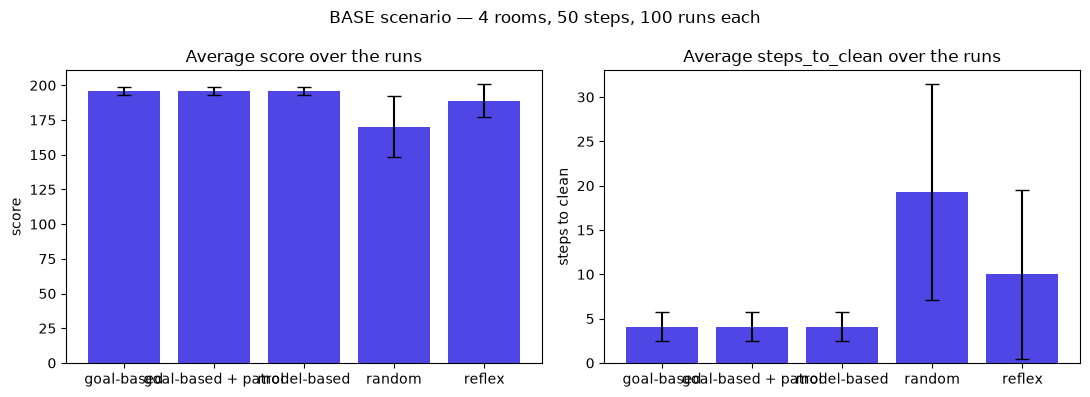

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bar_chart(summary, "score", ax=axes[0])
bar_chart(summary, "steps_to_clean", ax=axes[1])
fig.suptitle(f"BASE scenario — {BASE.n_rooms} rooms, {BASE.steps} steps, 100 runs each")
fig.tight_layout()
plt.show()

## ۴) سناریوی چالش (کثیفی مجدد + انرژی + حسگر نویزی)
این‌جاست که تفاوت واقعی سیاست‌ها دیده می‌شود.

In [6]:
ch_df, ch_summary = evaluate(AGENTS, CHALLENGE, runs=100)
ranked = ch_summary[("score", "mean")].sort_values(ascending=False)
table = ch_summary[[("score", "mean"), ("score", "std"), ("net_score", "mean"),
                    ("energy", "mean"), ("clean_ratio", "mean"), ("steps_to_clean", "mean")]].round(2)
table.columns = ["score", "std", "net_score", "energy", "clean_ratio", "steps_to_clean"]
table = table.loc[ranked.index]
print(table.to_string())

                      score    std  net_score  energy  clean_ratio  steps_to_clean
agent                                                                             
goal-based + patrol  161.19  14.24      84.47   76.72         0.79            8.77
reflex               141.13  20.39      66.89   74.24         0.70           14.32
random               103.80  26.42      19.66   84.14         0.52           20.89
goal-based            97.95  24.93      69.36   28.59         0.30            4.30
model-based           97.95  24.93      69.36   28.59         0.30            4.30


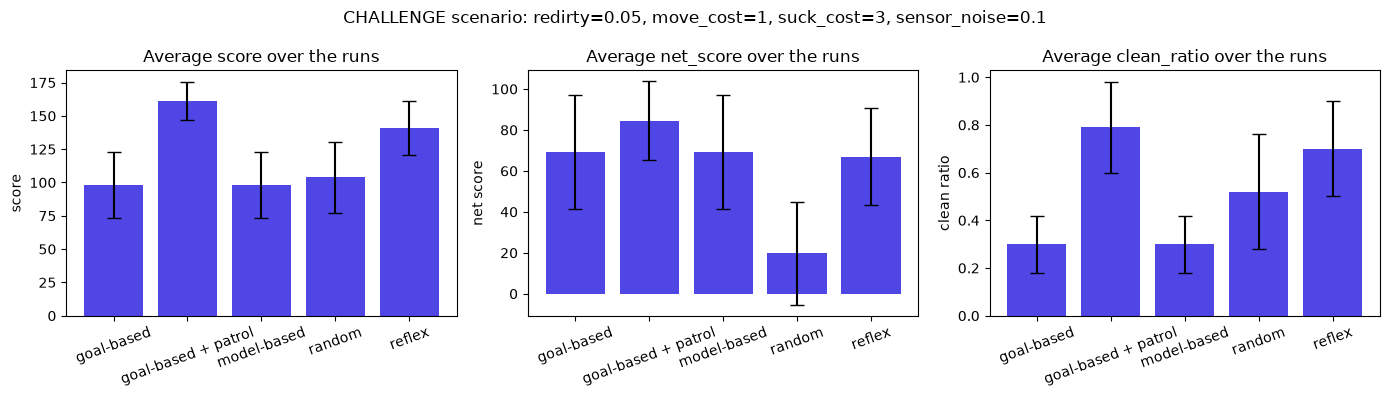

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
bar_chart(ch_summary, "score", ax=axes[0])
bar_chart(ch_summary, "net_score", ax=axes[1])
bar_chart(ch_summary, "clean_ratio", ax=axes[2])
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("CHALLENGE scenario: redirty=0.05, move_cost=1, suck_cost=3, sensor_noise=0.1")
fig.tight_layout()
plt.show()

## ۵) تحلیل

- **🎲 random** از ادراک استفاده نمی‌کند؛ دیر تمیز می‌کند و در سناریوی چالش با انرژی زیاد، `net_score` آن به‌شدت افت می‌کند.
- **⚡ reflex** فقط اتاق فعلی را می‌بیند؛ همیشه در حرکت است و برای همین کثیفیِ بازگشتی را «تصادفی» دوباره پیدا می‌کند — در چالش از model-based جلو می‌زند.
- **🧠 model-based** وقتی همه اتاق‌ها را تمیز بداند `NoOp` می‌دهد و می‌ایستد؛ ولی اگر کثیفی دوباره برگردد، متوجه نمی‌شود و امتیازش نزدیک اتاق‌های کثیف ثابت می‌ماند (همان نکته‌ای که در اسلاید مطرح شد).
- **🎯 goal-based** به‌جای جاروی کورِ رفت‌وبرگشت، به نزدیک‌ترین اتاق کثیف/ناشناخته می‌رود؛ در سناریوی پایه رفتار اولیه مشابه است، ولی در اتاق‌های بیشتر و سناریوهای پیچیده‌تر مسیر کوتاه‌تری دارد.
- **🔁 goal-based + patrol** دانش کهنه را بازمطالعه می‌کند: وقتی همه اتاق‌ها تمیز به‌نظر می‌رسند، به اتاقی می‌رود که قدیمی‌ترین شاهد را دارد. نتیجه در چالش: امتیاز و `clean_ratio` بالاتر از همه، به قیمت انرژی بیشتر — که دقیقاً همان «بازپرداخت» (trade-off) قابل مشاهده در `net_score` است.

**نتیجه:** در محیط ایستا «توقف با NoOp» درست است؛ در محیط پویا باید بازرسی ادامه داشته باشد.

## ۶) چه چیزی به پروژه «تشخیص ارقام دست‌نویس» منتقل می‌شود

| در این نوت‌بوک | در گام‌های ۴ تا ۷ پروژه گروه |
|---|---|
| `VacuumEnv` + `Observation` | داده MNIST: تصویر ۲۸×۲۸ + برچسب، تقسیم train/val/test |
| `Agent.act(obs)` | مدل: `forward(x) -> logits[10]` |
| `score += clean_rooms` | معیار: `accuracy` و `F1` (دفترچه `notes/risks.md`) |
| `evaluate(agents, cfg, runs)` با seed | همان حلقه روی ۵ seed برای baseline و شبکه عصبی |
| مقایسه ≥۲ روی یک چیدمان | مقایسه ≥۲ روش روی یک تقسیم‌بندی ثابت |
| `error bar` روی نمودار | `accuracy ± std` روی نمودار مقایسه |

کد این بسته در `src/vacuum_agent/` است و با دستور زیر هم بدون نوت‌بوک اجرا می‌شود:

```bash
PYTHONPATH=src python -m vacuum_agent.experiment --runs 100
```

خروجی: `results/runs_*.csv` و `results/vacuum_*.png`.